In [ ]:
!pip install -q transformers datasets evaluate torch torchvision matplotlib scikit-learn

In [ ]:
from datasets import load_dataset
from transformers import AutoImageProcessor
import torch
from torchvision.transforms import RandomResizedCrop, Compose, Normalize, ToTensor
from collections import Counter
import pandas as pd
import gc

# Forçar coleta de lixo residual anterior
gc.collect()

dataset = load_dataset("blanchon/EuroSAT_RGB", split="train[:50%]")

dataset = dataset.train_test_split(test_size=0.2, seed=42)
train_ds = dataset["train"]
val_ds = dataset["test"]

labels = train_ds.features["label"].names
label2id = {v: i for i, v in enumerate(labels)}
id2label = {i: v for i, v in enumerate(labels)}

# --- PRINT DE LABELS E PROPORÇÕES (OTIMIZADO PARA NÃO ESTOURAR A RAM) ---
print("--- Distribuição das Labels no Dataset de Treino ---")
# Acessar a coluna 'label' diretamente evita carregar e decodificar as imagens na memória RAM
train_labels = train_ds["label"]
counts = Counter(train_labels)
total = len(train_labels)
dist_df = pd.DataFrame([
    {
        "Label ID": i,
        "Label Nome": id2label[i],
        "Quantidade": counts[i],
        "Proporção (%)": round((counts[i] / total) * 100, 2)
    }
    for i in sorted(counts.keys())
])
display(dist_df)
# ------------------------------------

# Limpeza de variáveis temporárias
del train_labels
gc.collect()

model_checkpoint = "facebook/deit-tiny-patch16-224"
image_processor = AutoImageProcessor.from_pretrained(model_checkpoint)

normalize = Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
transforms = Compose([
    RandomResizedCrop(image_processor.size["height"]),
    ToTensor(),
    normalize,
])

def apply_transforms(examples):
    pixel_values = [transforms(img.convert("RGB")) for img in examples["image"]]
    return {"pixel_values": pixel_values, "labels": examples["label"]}

train_ds.set_transform(apply_transforms)
val_ds.set_transform(apply_transforms)

--- Distribuição das Labels no Dataset de Treino ---


,Label ID,Label Nome,Quantidade,Proporção (%)
0,0,Annual Crop,1431,22.08
1,1,Forest,1416,21.85
2,2,Herbaceous Vegetation,1466,22.62
3,3,Highway,1193,18.41
4,4,Industrial Buildings,974,15.03


In [ ]:
from transformers import AutoModelForImageClassification, TrainingArguments, Trainer
import evaluate
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix

# Limpar agressivamente a memória da GPU e CPU antes de começar
gc.collect()
torch.cuda.empty_cache()

# Carregar o Modelo Base (Desativado output_attentions durante o treino para não estourar a RAM na avaliação)
model = AutoModelForImageClassification.from_pretrained(
    model_checkpoint,
    num_labels=len(labels),
    label2id=label2id,
    id2label=id2label,
    output_attentions=False, # Mantido False para evitar acúmulo de tensores gigantescos na CPU durante o eval
    ignore_mismatched_sizes=True
)

metric_acc = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, label_ids = eval_pred
    predictions = np.argmax(predictions, axis=1)

    # Calcular Acurácia
    acc = metric_acc.compute(predictions=predictions, references=label_ids)["accuracy"]

    # Calcular F1-score (Weighted)
    f1 = f1_score(label_ids, predictions, average="weighted")

    # Calcular Matriz de Confusão
    cm = confusion_matrix(label_ids, predictions)

    print("\n--- Métricas da Época ---")
    print(f"Acurácia: {acc:.4f}")
    print(f"F1-Score (Weighted): {f1:.4f}")
    print("Matriz de Confusão:")
    print(cm)
    print("-------------------------\n")

    return {
        "accuracy": acc,
        "f1_score": f1
    }

def collate_fn(examples):
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    labels = torch.tensor([example["labels"] for example in examples])
    return {"pixel_values": pixel_values, "labels": labels}

args = TrainingArguments(
    output_dir="./vit-eurosat",
    remove_unused_columns=False,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16, # Podemos até subir um pouco o batch de treino
    per_device_eval_batch_size=8,   # Batch de eval otimizado
    eval_accumulation_steps=1,      # Limpa buffers da GPU/RAM frequentemente
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    dataloader_num_workers=0
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    data_collator=collate_fn,
)

trainer.train()

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([10, 192])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Score
1,No log,0.234905,0.940123,0.939673
2,0.236278,0.103027,0.973457,0.973371
3,0.107712,0.096770,0.974691,0.974632



--- Métricas da Época ---
Acurácia: 0.9401
F1-Score (Weighted): 0.9397
Matriz de Confusão:
[[339  12   6   1   2]
 [  0 371   0   0   0]
 [  2  20 310   0   1]
 [  8   6   5 260  33]
 [  0   0   1   0 243]]
-------------------------



...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- Métricas da Época ---
Acurácia: 0.9747
F1-Score (Weighted): 0.9746
Matriz de Confusão:
[[356   2   1   1   0]
 [  0 365   6   0   0]
 [  2   1 328   1   1]
 [  9   1   3 294   5]
 [  1   0   0   7 236]]
-------------------------



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=1215, training_loss=0.15445769196184575, metrics={'train_runtime': 183.9421, 'train_samples_per_second': 105.685, 'train_steps_per_second': 6.605, 'total_flos': 9.702929471864832e+16, 'train_loss': 0.15445769196184575, 'epoch': 3.0})

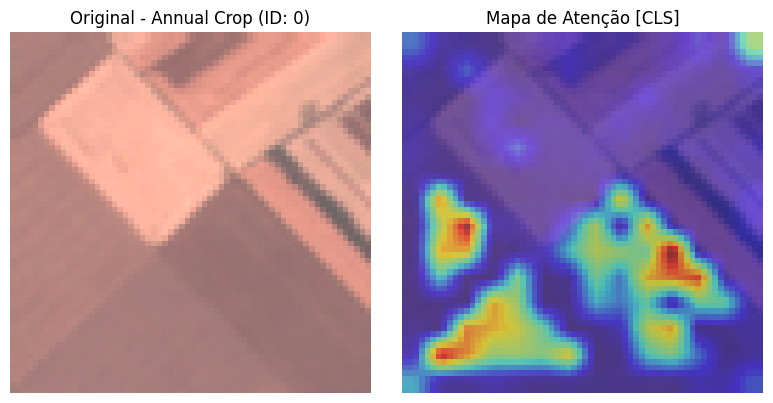

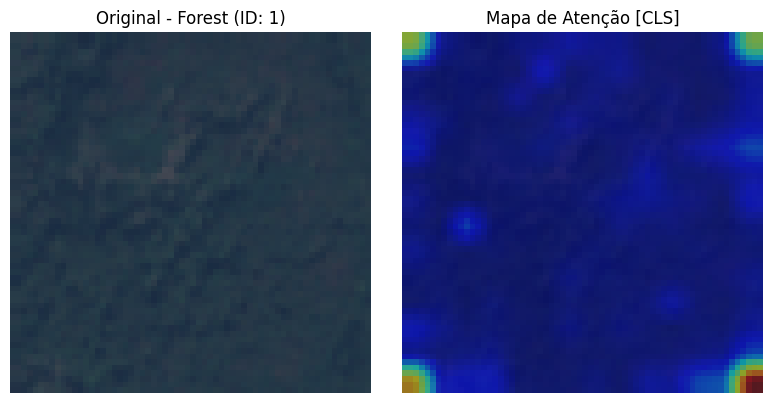

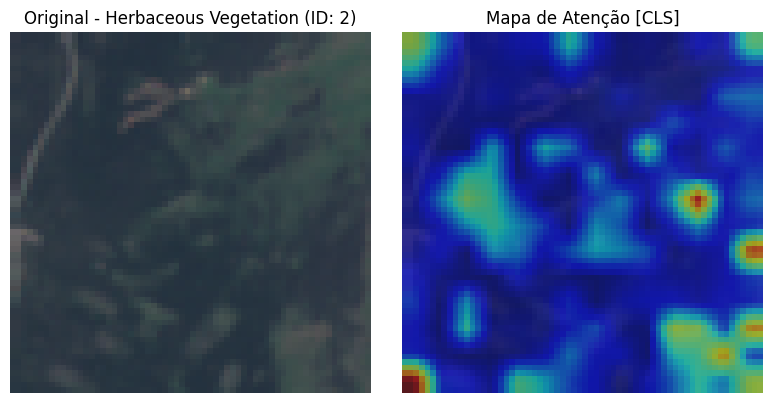

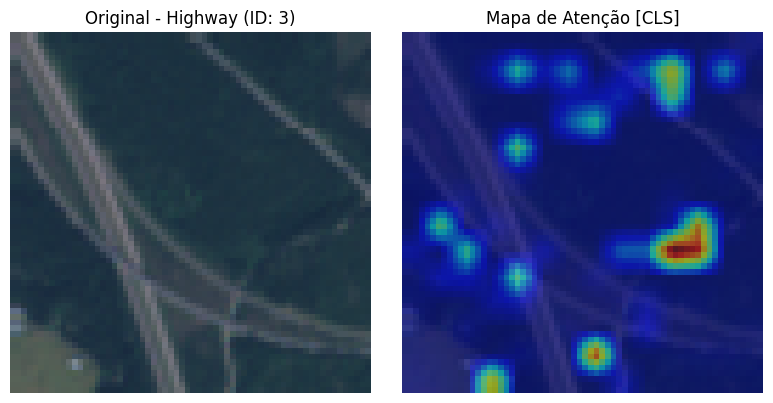

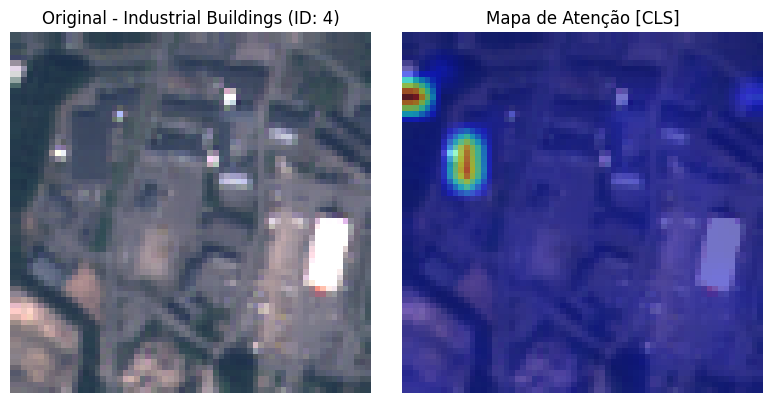

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import cv2

# Obter uma amostra de cada uma das labels disponíveis
val_ds.reset_format()

samples_per_label = {}
for idx in range(len(val_ds)):
    item = val_ds[idx]
    lbl = item["label"]
    if lbl not in samples_per_label:
        samples_per_label[lbl] = {"image": item["image"], "idx": idx}
    if len(samples_per_label) == len(labels):
        break

val_ds.set_transform(apply_transforms)

# Configurar o modelo para modo de avaliação com atenção
model.config._attn_implementation = "eager"
model.config.output_attentions = True
model.eval()
model.to("cuda" if torch.cuda.is_available() else "cpu")

# Iterar e plotar cada label e seu mapa de atenção correspondente
for lbl_id in sorted(samples_per_label.keys()):
    sample = samples_per_label[lbl_id]
    test_image = sample["image"]

    # Aplicar o transform manualmente para o modelo
    pixel_values = transforms(test_image.convert("RGB")).unsqueeze(0).to(model.device)

    with torch.no_grad():
        outputs = model(pixel_values)

    # Pegando as atenções da última camada (último bloco do Transformer)
    attentions = outputs.attentions[-1] # (batch_size, num_heads, seq_len, seq_len)

    mean_attention = attentions[0, :, 0, 1:].mean(dim=0)
    attention_map = mean_attention.reshape(14, 14).cpu().numpy()

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(test_image)
    ax[0].set_title(f"Original - {id2label[lbl_id]} (ID: {lbl_id})")
    ax[0].axis("off")

    # Redimensionar o mapa de atenção para coincidir com o tamanho da imagem original
    attention_map_resized = cv2.resize(attention_map, (test_image.size[0], test_image.size[1]))

    ax[1].imshow(test_image)
    ax[1].imshow(attention_map_resized, cmap='jet', alpha=0.55)
    ax[1].set_title(f"Mapa de Atenção [CLS]")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()